# Komparasi_EulerRPY_1949_EKF-IMU-MAG-Palm_vs_EST-UNIX-3DM-GX5-25

Perbandingan **roll / pitch / yaw** dari EKF accel + gyro + magnetometer pada log Palm (`PLG1 v4`) terhadap estimasi 3DM-GX5-25, sesi **1949**.

- Palm: `261109194905.bin`.
- Acuan: `SensorConnectData_EST_Unix_1949.csv` (waktu Unix, sudut dalam **rad**).
- Sumbu Palm: **X+ sama, Y+ dan Z+ dibalik**, untuk accel, gyro, dan mag.
- Magnetometer dipakai mentah dalam µT, tanpa kalibrasi hard-iron/soft-iron. Acuan medan `ahrs` memakai bawaan pustaka.
- `ahrs` NED membandingkan akselerometer dengan `[0, 0, +1]`. Sensor membaca gaya spesifik (Z ≈ −1 g), jadi **tanda akselerasi dibalik hanya untuk EKF**. Gyro dan mag tidak ikut dibalik.
- `start_unix_ms` Palm adalah jam dinding WIB yang ditulis sebagai angka Unix. EST adalah Unix UTC, jadi waktu Palm digeser **−7 jam**.


In [1]:
from pathlib import Path
import struct

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ahrs.filters import EKF
from scipy.spatial.transform import Rotation

ROOT = Path(r"D:/Pengujian/Swimmer_Monitoring/Palm_Pressure_Motion")
PALM_BIN = ROOT / "Vs_3DM-GX5-25_Data" / "Palm_Sensor" / "261109194905.bin"
EST_CSV = ROOT / "Vs_3DM-GX5-25_Data" / "3DM-GX5-25_EST" / "SensorConnectData_EST_Unix_1949.csv"
USE_MAG = True

G = 9.80665
HEADER_SIZE = 256
RECORD_SIZE = 26


## 1. Baca log Palm

Header 256 B: magic `PLG1`, versi, periode, `start_unix_ms` di offset 22.
Rekaman 26 B: `t_rel_ms` u32 + 11×int16.

- d3..d5 accel, satuan **mg**
- d6..d8 gyro, satuan **0,1 °/s**
- d9..d11 magnetometer, satuan **µT**


In [2]:
def parse_plg1(path: Path) -> pd.DataFrame:
    raw = path.read_bytes()
    magic, version, period_ms, channels, rec_size = struct.unpack_from("<4sHHBB", raw, 0)
    if magic != b"PLG1" or version < 4 or rec_size != RECORD_SIZE:
        raise ValueError(f"bukan PLG1 v4: {magic!r} v={version} rec={rec_size}")
    start_unix_ms = struct.unpack_from("<Q", raw, 22)[0]
    rows = []
    offset = HEADER_SIZE
    while offset + RECORD_SIZE <= len(raw):
        t_rel, *ch = struct.unpack_from("<I11h", raw, offset)
        rows.append((t_rel, *ch))
        offset += RECORD_SIZE
    cols = ["t_rel_ms"] + [f"d{i}" for i in range(1, 12)]
    df = pd.DataFrame(rows, columns=cols)
    df["unix_ms"] = start_unix_ms + df["t_rel_ms"]
    df["t_s"] = df["unix_ms"] / 1000.0
    print(
        f"Palm {path.name}: {len(df)} sampel, period={period_ms} ms, "
        f"start_unix_ms={start_unix_ms}"
    )
    print(f"  rentang {df['t_s'].iloc[0]:.3f} .. {df['t_s'].iloc[-1]:.3f} s")
    return df

palm = parse_plg1(PALM_BIN)
palm.head()


Palm 261109194905.bin: 8617 sampel, period=10 ms, start_unix_ms=1794253745055
  rentang 1794253745.065 .. 1794253829.206 s


,t_rel_ms,d1,d2,d3,d4,d5,d6,d7,d8,d9,d10,d11,unix_ms,t_s
0,10,0,0,-35,20,1004,20,6,-2,-6,9,51,1794253745065,1.794254e+09
1,20,0,0,-34,23,994,10,-7,-2,-6,9,51,1794253745075,1.794254e+09
2,30,0,0,-33,20,1004,-2,-9,-2,-6,9,51,1794253745085,1.794254e+09
3,39,0,0,-34,18,1015,-9,-11,-3,-6,8,51,1794253745094,1.794254e+09
4,49,0,0,-33,17,1024,-12,-12,-3,-6,9,51,1794253745104,1.794254e+09


## 2. Satuan dan sumbu

Accel ke m/s², gyro ke rad/s. Magnetometer tetap µT. `Y` dan `Z` dibalik.


In [3]:
axis = np.array([1.0, -1.0, -1.0])
acc_g = palm[["d3", "d4", "d5"]].to_numpy(dtype=float) / 1000.0 * axis
gyr_rads = np.deg2rad(palm[["d6", "d7", "d8"]].to_numpy(dtype=float) * 0.1) * axis
mag_uT = palm[["d9", "d10", "d11"]].to_numpy(dtype=float) * axis
acc_ms2 = -acc_g * G

print("Accel mean (g) setelah remap sumbu:", acc_g.mean(axis=0))
print("Accel mean (g) yang masuk EKF:", (-acc_g).mean(axis=0))
print("Accel |a| mean (g):", np.linalg.norm(acc_g, axis=1).mean())
print("Gyro mean (rad/s):", gyr_rads.mean(axis=0))
print("Mag mean (µT):", mag_uT.mean(axis=0))
print("|Mag| mean (µT):", np.linalg.norm(mag_uT, axis=1).mean())


Accel mean (g) setelah remap sumbu: [-0.04310851  0.01789068 -0.99973645]
Accel mean (g) yang masuk EKF: [ 0.04310851 -0.01789068  0.99973645]
Accel |a| mean (g): 1.0251899876539496
Gyro mean (rad/s): [ 0.00115592 -0.00122904  0.00947262]
Mag mean (µT): [  1.21550424  -7.76256238 -46.57224092]
|Mag| mean (µT): 48.88131216004696


## 3. EKF IMU + mag

`ahrs.filters.EKF`, frekuensi dari median `Δt` Palm.
Quaternion `[w, x, y, z]` diubah ke Euler ZYX (yaw, pitch, roll) dalam radian.


In [4]:
dt = np.diff(palm["t_s"].to_numpy())
dt = dt[dt > 0]
freq = 1.0 / np.median(dt)
print(f"Frekuensi Palm: {freq:.2f} Hz (median dt={np.median(dt)*1000:.2f} ms)")

kwargs = dict(gyr=gyr_rads, acc=acc_ms2, frequency=float(freq))
if USE_MAG:
    kwargs["mag"] = mag_uT
ekf = EKF(**kwargs)
q_xyzw = np.column_stack([ekf.Q[:, 1], ekf.Q[:, 2], ekf.Q[:, 3], ekf.Q[:, 0]])
euler = Rotation.from_quat(q_xyzw).as_euler("ZYX", degrees=False)
palm = palm.copy()
palm["yaw"] = euler[:, 0]
palm["pitch"] = euler[:, 1]
palm["roll"] = euler[:, 2]
print(palm[["roll", "pitch", "yaw"]].describe())


Frekuensi Palm: 100.00 Hz (median dt=10.00 ms)


              roll        pitch          yaw
count  8617.000000  8617.000000  8617.000000
mean     -0.309971    -0.080672     1.693989
std       0.159372     0.171294     0.338533
min      -0.906208    -0.800014     1.147761
25%      -0.354376    -0.152003     1.437227
50%      -0.291496    -0.068978     1.572477
75%      -0.261069     0.005607     2.091646
max       0.413447     0.343754     2.464516


## 4. Baca EST 3DM (Unix)

Header SensorConnect dilewati sampai `DATA_START`. Sudut estimasi sudah dalam radian.


In [5]:
def read_est_unix(path: Path) -> pd.DataFrame:
    lines = path.read_text(encoding="utf-8", errors="replace").splitlines()
    start = next(i for i, line in enumerate(lines) if line.startswith("DATA_START"))
    header = lines[start + 1].split(",")
    rows = [line.split(",") for line in lines[start + 2 :] if line.strip()]
    df = pd.DataFrame(rows, columns=header)
    rename = {}
    for col in df.columns:
        if col == "Time" or col.endswith(":valid"):
            continue
        rename[col] = col.split(":")[-1]
    df = df.rename(columns=rename)
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df["t_s"] = df["Time"] / 1e9
    keep = ["t_s", "estRoll", "estPitch", "estYaw"]
    df = df[keep].dropna()
    print(f"EST {path.name}: {len(df)} sampel")
    print(f"  rentang {df['t_s'].iloc[0]:.3f} .. {df['t_s'].iloc[-1]:.3f} s")
    return df

est = read_est_unix(EST_CSV)
est.head()


EST SensorConnectData_EST_Unix_1949.csv: 13122 sampel
  rentang 1794228540.546 .. 1794228719.533 s


,t_s,estRoll,estPitch,estYaw
0,1.794229e+09,0.001829,-0.000268,-1.41298
1,1.794229e+09,0.001829,-0.000268,-1.41298
2,1.794229e+09,0.001829,-0.000268,-1.41298
3,1.794229e+09,0.001829,-0.000268,-1.41298
4,1.794229e+09,0.001829,-0.000268,-1.41298


## 5. Selaraskan waktu

Waktu Palm dikurangi 7 jam. Sisa offset (detik, ditambahkan ke waktu Palm)
dicari di ±5 s supaya korelasi pitch maksimum. Selisih sudut dibungkus ke (−π, π].


In [6]:
def wrap(angle):
    return (angle + np.pi) % (2 * np.pi) - np.pi


def interp_est(est_df, t_query):
    out = {}
    for src, dst in (("estRoll", "roll"), ("estPitch", "pitch"), ("estYaw", "yaw")):
        out[dst] = np.interp(
            t_query,
            est_df["t_s"].to_numpy(),
            est_df[src].to_numpy(),
            left=np.nan,
            right=np.nan,
        )
    return pd.DataFrame(out)


WIB_OFFSET_S = 7 * 3600
palm_utc = palm["t_s"].to_numpy() - WIB_OFFSET_S
print(
    f"Palm sebagai WIB-as-UTC: {palm['t_s'].iloc[0]:.3f} .. {palm['t_s'].iloc[-1]:.3f}"
)
print(f"Palm setelah -7 jam:     {palm_utc[0]:.3f} .. {palm_utc[-1]:.3f}")


def score_offset(offset_s):
    aligned = interp_est(est, palm_utc + offset_s)
    mask = aligned["pitch"].notna().to_numpy()
    if mask.sum() < 50:
        return -np.inf
    return float(np.corrcoef(palm.loc[mask, "pitch"], aligned.loc[mask, "pitch"])[0, 1])


grid = np.arange(-5.0, 5.0 + 1e-9, 0.01)
scores = np.array([score_offset(dt_off) for dt_off in grid])
best = float(grid[int(np.nanargmax(scores))])
print(f"Sisa offset: {best:+.3f} s (korelasi pitch={np.nanmax(scores):.4f})")

est_on_palm = interp_est(est, palm_utc + best)
valid = est_on_palm["roll"].notna().to_numpy()
print(f"Sampel overlap: {int(valid.sum())} / {len(palm)}")


Palm sebagai WIB-as-UTC: 1794253745.065 .. 1794253829.206
Palm setelah -7 jam:     1794228545.065 .. 1794228629.206


Sisa offset: -0.110 s (korelasi pitch=0.7165)
Sampel overlap: 8617 / 8617


## 6. Metrik

Dua baris per sumbu: selisih langsung, lalu setelah mean-bias
(rata-rata selisih dibungkus dikurangi dari sudut Palm).


In [7]:
def metrics(ref, got, debias=False):
    err = wrap(got - ref)
    if debias:
        err = wrap(err - np.mean(err))
    ref_c = ref - np.mean(ref)
    got_c = got - np.mean(got)
    corr = float(np.corrcoef(ref_c, got_c)[0, 1]) if len(ref) > 2 else np.nan
    return {
        "n": int(len(err)),
        "corr": corr,
        "mae_deg": float(np.rad2deg(np.mean(np.abs(err)))),
        "rmse_deg": float(np.rad2deg(np.sqrt(np.mean(err**2)))),
        "bias_deg": float(np.rad2deg(np.mean(err))),
    }


rows = []
for name in ("roll", "pitch", "yaw"):
    ref = est_on_palm.loc[valid, name].to_numpy()
    got = palm.loc[valid, name].to_numpy()
    rows.append({"axis": name, "stage": "langsung", **metrics(ref, got)})
    rows.append({"axis": name, "stage": "setelah bias", **metrics(ref, got, debias=True)})

summary = pd.DataFrame(rows)
summary


,axis,stage,n,corr,mae_deg,rmse_deg,bias_deg
0,roll,langsung,8617,0.988125,15.932826,15.996129,-1.593258e+01
1,roll,setelah bias,8617,0.988125,1.021974,1.424418,1.202978e-14
2,pitch,langsung,8617,0.716520,6.764887,7.733526,-3.434606e+00
3,pitch,setelah bias,8617,0.716520,5.979356,6.928991,-9.921470e-16
4,yaw,langsung,8617,-0.501971,155.347977,155.710333,5.322757e+01
5,yaw,setelah bias,8617,-0.501971,114.137171,116.567921,1.141372e+02


## 7. Plot

Waktu diplot relatif terhadap awal overlap, dalam detik.


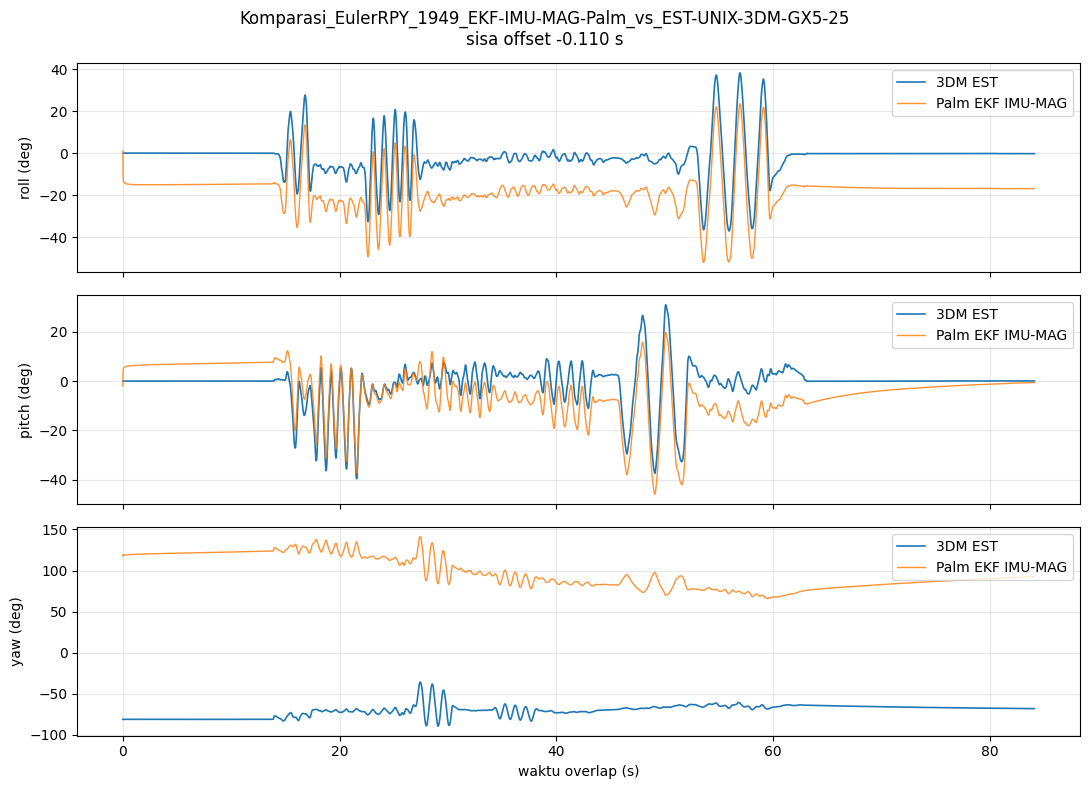

In [8]:
t_aligned = palm_utc + best
t0 = t_aligned[valid][0]
t_rel = t_aligned[valid] - t0
label = "Palm EKF IMU-MAG"

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, name in zip(axes, ("roll", "pitch", "yaw")):
    ax.plot(t_rel, np.rad2deg(est_on_palm.loc[valid, name]), label="3DM EST", lw=1.2)
    ax.plot(t_rel, np.rad2deg(palm.loc[valid, name]), label=label, lw=1.0, alpha=0.85)
    ax.set_ylabel(f"{name} (deg)")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("waktu overlap (s)")
fig.suptitle("Komparasi_EulerRPY_1949_EKF-IMU-MAG-Palm_vs_EST-UNIX-3DM-GX5-25\nsisa offset " + f"{best:+.3f} s")
fig.tight_layout()
plt.show()
